# Implementasi Bab 1 — Konsep Dasar Machine Learning

Alur pertama machine learning: memuat data, eksplorasi, split, training KNN, evaluasi, dan visualisasi Iris [ML-MODUL-01, hlm. 14–15].


In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Library berhasil dimuat.")


Library berhasil dimuat.


In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["target_name"] = df["target"].map(dict(enumerate(iris.target_names)))
print("Ukuran dataset:", df.shape)
display(df.head())


Ukuran dataset: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print("Missing value:")
print(df.isna().sum())
print("\nJumlah data per kelas:")
print(df["target_name"].value_counts())

X = df[iris.feature_names]
y = df["target"]


Missing value:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
target_name          0
dtype: int64

Jumlah data per kelas:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)
print("Model dilatih pada", X_train.shape[0], "data.")


Model dilatih pada 120 data.


In [5]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi test: {accuracy:.2%}")
print(classification_report(y_test, y_pred, target_names=iris.target_names))


Akurasi test: 100.00%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



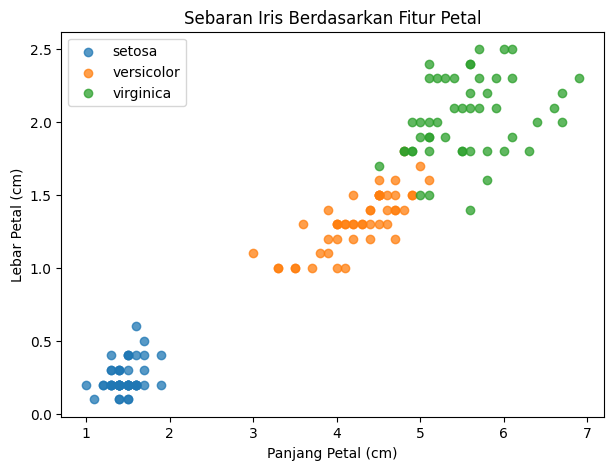

In [6]:
plt.figure(figsize=(7, 5))
for target_value, target_name in enumerate(iris.target_names):
    subset = df[df["target"] == target_value]
    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=target_name,
        alpha=0.75,
    )
plt.xlabel("Panjang Petal (cm)")
plt.ylabel("Lebar Petal (cm)")
plt.title("Sebaran Iris Berdasarkan Fitur Petal")
plt.legend()
plt.show()


## Latihan mandiri: pengaruh nilai k

K kecil cenderung sensitif terhadap noise, sedangkan k terlalu besar dapat mengaburkan batas kelas. Eksperimen berikut merupakan pelengkap untuk menghubungkan pengantar Bab 1 dengan pembahasan KNN pada Bab 6.


k terbaik menurut CV training: 5
Akurasi test final: 1.000


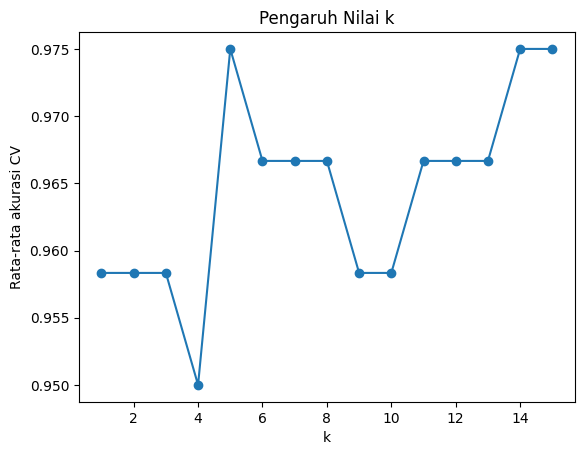

In [7]:
k_values = range(1, 16)
k_cv_scores = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for k in k_values:
    candidate = KNeighborsClassifier(n_neighbors=k)
    k_cv_scores.append(cross_val_score(candidate, X_train, y_train, cv=cv).mean())

best_k = list(k_values)[int(np.argmax(k_cv_scores))]
selected_knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
final_test_accuracy = accuracy_score(y_test, selected_knn.predict(X_test))
print(f"k terbaik menurut CV training: {best_k}")
print(f"Akurasi test final: {final_test_accuracy:.3f}")
plt.plot(list(k_values), k_cv_scores, marker="o")
plt.xlabel("k")
plt.ylabel("Rata-rata akurasi CV")
plt.title("Pengaruh Nilai k")
plt.show()


## Kesimpulan

Notebook menunjukkan pola kerja end-to-end paling sederhana: data → eksplorasi → split → training → evaluasi. Akurasi tinggi pada Iris masuk akal karena kelas relatif terpisah pada fitur petal [ML-MODUL-01, hlm. 15].
